# Prétraitement d’image Sentinel-2 L2A avec Cartomize

Ce tutoriel présente un flux reproductible de diagnostic et de prétraitement d’images Sentinel-2 L2A avec Cartomize. Il couvre l’inventaire des données d’entrée, le contrôle des métadonnées, l’évaluation de la couverture spatiale, le diagnostic de qualité, le masquage des nuages, la sélection de l’acquisition, le découpage à l’emprise d’étude et la production des résultats dérivés.

Les résultats présentés proviennent de données Sentinel-2 réelles. Les informations de provenance sont enregistrées dans `data/provenance.json`.

> L’emprise utilisée correspond à une fenêtre d’analyse située à Kinshasa et ne constitue pas une limite administrative.

## 1. Données d’entrée

Les données d’entrée comprennent l’emprise d’étude, l’acquisition Sentinel-2 L2A, les bandes spectrales, le masque de qualité et les métadonnées nécessaires au prétraitement.

In [1]:
from pathlib import Path
import json, shutil
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import box
import rasterio
from rasterio.mask import mask
from rasterio.warp import reproject, Resampling
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage
import cartomize as cm

ROOT = Path.cwd()
if ROOT.name != "demonstration-carto":
    source = ROOT / "demonstration-carto"
    if source.is_dir():
        ROOT = source
DATA = ROOT / "data"
RESULTS = ROOT / "results"
if not (DATA / "provenance.json").is_file():
    raise FileNotFoundError("Données réelles absentes : exécuter download_real_data.py avant le notebook.")
if RESULTS.exists():
    shutil.rmtree(RESULTS)
RESULTS.mkdir()
provenance = json.loads((DATA / "provenance.json").read_text(encoding="utf-8"))
aoi = gpd.read_file(DATA / "aoi.geojson")
input_info = provenance["input_scene"]

print("=== INVENTAIRE DES DONNÉES D’ENTRÉE ===")
print("Zone d'étude :", DATA / "aoi.geojson")
print("CRS zone :", aoi.crs)
print("Étendue zone :", tuple(round(v, 6) for v in aoi.total_bounds))
print()
print("Acquisition Sentinel-2 :", input_info["item_id"])
print("Date d’acquisition :", input_info["datetime"])
print("Couverture nuageuse globale :", round(input_info["global_cloud_cover_percent"], 3), "%")
print("Pixels utilisables sur l’emprise :", round(input_info["aoi_hybrid_usable_percent"], 3), "%")
print()
print("Plateforme :", provenance["platform"])
print("Tuile MGRS :", provenance["mgrs_tile"])
print("Nuages globaux scène retenue :", round(provenance["global_cloud_cover_percent"], 3), "%")
print("Qualité hybride AOI retenue :", round(provenance["aoi_hybrid_usable_percent_before_processing"], 3), "%")

=== INVENTAIRE DES DONNÉES D’ENTRÉE ===
Zone d'étude : /home/runner/work/cartomize-python/cartomize-python/demonstration-carto/data/aoi.geojson
CRS zone : EPSG:4326
Étendue zone : (np.float64(15.28), np.float64(-4.34), np.float64(15.34), np.float64(-4.28))

Acquisition Sentinel-2 : S2C_33MWR_20250620_0_L2A
Date d’acquisition : 2025-06-20T09:22:05.004000Z
Couverture nuageuse globale : 1.767 %
Pixels utilisables sur l’emprise : 98.081 %

Plateforme : sentinel-2c
Tuile MGRS : None
Nuages globaux scène retenue : 1.767 %
Qualité hybride AOI retenue : 98.081 %


## 2. Contrôle des bandes et des métadonnées

Le contrôle préalable porte sur l’identification des bandes, le système de coordonnées de référence, la résolution spatiale, le type numérique, les unités et les paramètres de calibration. Ces informations conditionnent la validité des étapes de prétraitement.

In [2]:
scene = cm.load_scenes_manifest(DATA / "scenes.json")[0]
rows = []
for name, band in scene.bands.items():
    with rasterio.open(band.path) as src:
        rows.append({
            "bande": name,
            "fichier": Path(band.path).name,
            "largeur": src.width,
            "hauteur": src.height,
            "crs": str(src.crs),
            "resolution": src.res,
            "dtype": src.dtypes[0],
            "scale": band.scale,
            "offset": band.offset,
            "unite": band.unit,
        })
display(pd.DataFrame(rows))
print("Masque qualité :", Path(scene.quality).name, "|", scene.quality_kind)
print("Notes de calibration :")
for note in scene.notes:
    print("-", note)

,bande,fichier,largeur,hauteur,crs,resolution,dtype,scale,offset,unite
0,blue,B02.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
1,green,B03.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
2,red,B04.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
3,nir,B08.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
4,swir1,B11.tif,334,332,EPSG:32733,"(20.0, 20.0)",uint16,0.0001,0.0,reflectance


Masque qualité : SCL.tif | sentinel_scl
Notes de calibration :
- Earth Search COG harmonisé blue : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé green : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé red : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé nir : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé swir16 : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.


## 3. Emprise d’étude et couverture spatiale

L’acquisition Sentinel-2 utilisée pour le traitement couvre Kinshasa et dépasse l’emprise d’étude. La composition en couleurs naturelles est affichée sur une étendue plus large, avec l’emprise superposée, afin d’évaluer la couverture spatiale et de déterminer si un découpage est requis.

In [3]:
input_dir = DATA / "input_scene"

def read_reflectance(path, scale=0.0001, offset=0.0):
    with rasterio.open(path) as src:
        arr = src.read(1).astype("float64")
        nodata = src.nodata
        transform0 = src.transform
        crs0 = src.crs
        bounds0 = src.bounds
    valid = np.isfinite(arr)
    if nodata is not None:
        valid &= arr != nodata
    out = arr * scale + offset
    out[~valid] = np.nan
    return out, transform0, crs0, bounds0

blue0, _, _, _ = read_reflectance(input_dir / "B02.tif")
green0, _, _, _ = read_reflectance(input_dir / "B03.tif")
red0, _, _, bounds0 = read_reflectance(input_dir / "B04.tif")

stack0 = np.dstack([red0, green0, blue0])
valid0 = np.isfinite(stack0).all(axis=2)
rgb0 = np.zeros((*stack0.shape[:2], 3), dtype="uint8")
for i in range(3):
    values = stack0[..., i][valid0]
    low, high = np.quantile(values, [0.02, 0.98])
    scaled = np.clip((stack0[..., i] - low) / max(high - low, 1e-9), 0, 1)
    rgb0[..., i] = np.nan_to_num(scaled * 255).astype("uint8")

with rasterio.open(input_dir / "B04.tif") as src:
    aoi_plot = aoi.to_crs(src.crs)
    xmin, ymin, xmax, ymax = src.bounds

scene_geom = box(xmin, ymin, xmax, ymax)
aoi_union = aoi_plot.geometry.union_all()
coverage_pct = 100.0 * aoi_union.intersection(scene_geom).area / aoi_union.area
scene_width_km = (xmax - xmin) / 1000.0
scene_height_km = (ymax - ymin) / 1000.0
aoi_bounds = aoi_plot.total_bounds
aoi_width_km = (aoi_bounds[2] - aoi_bounds[0]) / 1000.0
aoi_height_km = (aoi_bounds[3] - aoi_bounds[1]) / 1000.0

print("=== ÉVALUATION DE LA COUVERTURE SPATIALE ===")
print(f"Dimensions scène : {scene_width_km:.2f} × {scene_height_km:.2f} km")
print(f"Dimensions AOI   : {aoi_width_km:.2f} × {aoi_height_km:.2f} km")
print(f"AOI couverte par la scène : {coverage_pct:.2f} %")
print("Décision :", "Découpage nécessaire : la scène déborde l'AOI." if coverage_pct >= 99.9 else "Scène complémentaire nécessaire.")

fig, axes = plt.subplots(1, 2, figsize=(18, 7), constrained_layout=True)

# Zone seule : remplissage translucide + contour.
aoi_plot.plot(ax=axes[0], alpha=0.35)
aoi_plot.boundary.plot(ax=axes[0], linewidth=2)
axes[0].set_title("Emprise d’étude")
axes[0].set_aspect("equal")
axes[0].axis("off")

# Scène complète avec zone superposée.
axes[1].imshow(rgb0, extent=[xmin, xmax, ymin, ymax])
aoi_plot.plot(ax=axes[1], alpha=0.18)
aoi_plot.boundary.plot(ax=axes[1], linewidth=2)
axes[1].set_title(
    f"Sentinel-2 L2A — Kinshasa\n"
    f"Couverture de l’emprise : {coverage_pct:.2f} % — découpage requis"
)
axes[1].axis("off")

fig.savefig(RESULTS / "kinshasa_scene_input.png", dpi=180, bbox_inches="tight")
plt.show()

display(pd.DataFrame([{
    "scene": input_info["item_id"],
    "date": input_info["datetime"],
    "couvre_AOI_%": input_info["aoi_scl_usable_percent"],
    "nuages_spectraux_AOI_%": input_info["aoi_spectral_cloud_percent"],
    "qualite_hybride_AOI_%": input_info["aoi_hybrid_usable_percent"],
    "couverture_geometrique_AOI_%": coverage_pct,
    "scene_largeur_km": scene_width_km,
    "scene_hauteur_km": scene_height_km,
    "AOI_largeur_km": aoi_width_km,
    "AOI_hauteur_km": aoi_height_km,
        "action_spatiale": "découpage" if coverage_pct >= 99.9 else "acquisition_complémentaire",
}]))

=== ÉVALUATION DE LA COUVERTURE SPATIALE ===
Dimensions scène : 12.22 × 12.18 km
Dimensions AOI   : 6.66 × 6.63 km
AOI couverte par la scène : 100.00 %
Décision : Découpage nécessaire : la scène déborde l'AOI.


,scene,date,couvre_AOI_%,nuages_spectraux_AOI_%,qualite_hybride_AOI_%,couverture_geometrique_AOI_%,scene_largeur_km,scene_hauteur_km,AOI_largeur_km,AOI_hauteur_km,action_spatiale
0,S2C_33MWR_20250620_0_L2A,2025-06-20T09:22:05.004000Z,98.931354,1.252913,98.081005,100.0,12.22,12.18,6.660536,6.634984,découpage


![Acquisition Sentinel-2 L2A et emprise d’étude à Kinshasa](./results/kinshasa_scene_input.png)

## 4. Diagnostic automatique N1→N5

Le prétraitement automatique est organisé en cinq niveaux :

- **N1 — Calibration radiométrique** ;
- **N2 — Correction atmosphérique** ;
- **N3 — Contrôle de qualité** ;
- **N4 — Détection et masquage des nuages et pixels non utilisables** ;
- **N5 — Sélection des scènes, harmonisation, mosaïquage éventuel et découpage**.

Le journal d’exécution synthétise les contrôles, décisions et opérations appliqués au cours du traitement.

In [4]:
journal = []
def log_stage(message):
    journal.append(str(message))
    print(str(message))

prepared = cm.preprocess_imagery(
    DATA,
    RESULTS / "preprocessed",
    aoi=DATA / "aoi.geojson",
    band_order=["blue", "green", "red", "nir"],
    coverage_threshold=95,
    allow_partial=False,
    mask_clouds=True,
    mask_saturation=False,
    multiband=True,
    separate_bands=True,
    composition="natural",
    stage=log_stage,
)
print("Statut :", prepared.report["status"])
print("Scènes retenues :", prepared.report["selected_scene_ids"])
print("Couverture utile :", round(prepared.report["usable_percent"], 3), "%")
print("Mosaïque :", prepared.report["mosaic"])
print("Rapport :", prepared.manifest)
product = prepared.products[0]
display(pd.DataFrame([product]))
quality_rows = []
spectral_rows = []
for item in prepared.diagnostic.report.get("scenes", []):
    quality = item.get("quality_statistics")
    if quality:
        quality_rows.append({
            "scene": item["id"],
            "type_masque": quality["kind"],
            "pixels_nuageux_SCL": quality.get("cloud_pixels"),
            "nuages_SCL_%": quality.get("cloud_percent"),
            "SCL7_faible_proba": quality.get("cloud_low_probability_pixels"),
            "SCL8_moyenne_proba": quality.get("cloud_medium_probability_pixels"),
            "SCL9_haute_proba": quality.get("cloud_high_probability_pixels"),
            "cirrus": quality.get("cirrus_pixels"),
            "ombres": quality.get("cloud_shadow_pixels"),
            "neige": quality.get("snow_pixels"),
        })
    spectral = item.get("spectral_cloud_statistics")
    if spectral:
        spectral_rows.append({
            "scene": item["id"],
            "methode": spectral.get("method"),
            "pixels_evalues": spectral.get("evaluated_pixels"),
            "nuages_supplementaires": spectral.get("cloud_pixels"),
            "nuages_supplementaires_%": spectral.get("cloud_percent"),
            "pixels_clairs": spectral.get("clear_pixels"),
            "pixels_sans_diagnostic": spectral.get("nodata_pixels"),
        })
print("Diagnostic SCL officiel")
display(pd.DataFrame(quality_rows))
print("Détection spectrale supplémentaire")
display(pd.DataFrame(spectral_rows))
print("Pixels utilisables après combinaison des masques :", prepared.diagnostic.report["usable_pixels"])
print("Pixels rejetés au total :", prepared.diagnostic.report["present_pixels"] - prepared.diagnostic.report["usable_pixels"])


N1 — Diagnostic radiométrique
N2 — Diagnostic atmosphérique
N3 — Contrôle qualité
N4 — Diagnostic nuages et pixels non utilisables
N4 — Détection spectrale de secours : 5561 pixels (1.256 %) pour S2C_33MWR_20250620_0_L2A
Contrôle des bandes, des masques et de la couverture utile


N5 — Préparation des scènes retenues
Prétraitement multispectral ; 1/1


Extraction des bandes
Composition colorée


Statut : partial
Scènes retenues : ['S2C_33MWR_20250620_0_L2A']
Couverture utile : 98.081 %
Mosaïque : False
Rapport : /home/runner/work/cartomize-python/cartomize-python/demonstration-carto/results/preprocessed/preprocessing.json


,scenes,multiband,bands,composition,source_index,report
0,[S2C_33MWR_20250620_0_L2A],/home/runner/work/cartomize-python/cartomize-p...,"{'1': {'name': 'blue', 'path': '/home/runner/w...",/home/runner/work/cartomize-python/cartomize-p...,/home/runner/work/cartomize-python/cartomize-p...,/home/runner/work/cartomize-python/cartomize-p...


Diagnostic SCL officiel


,scene,type_masque,pixels_nuageux_SCL,nuages_SCL_%,SCL7_faible_proba,SCL8_moyenne_proba,SCL9_haute_proba,cirrus,ombres,neige
0,S2C_33MWR_20250620_0_L2A,sentinel_scl,1992,0.450647,28,316,1648,0,2776,0


Détection spectrale supplémentaire


,scene,methode,pixels_evalues,nuages_supplementaires,nuages_supplementaires_%,pixels_clairs,pixels_sans_diagnostic
0,S2C_33MWR_20250620_0_L2A,sentinel_spectral_fallback_v1,442031,5557,1.257152,436474,0


Pixels utilisables après combinaison des masques : 433549
Pixels rejetés au total : 8482


### Lecture du diagnostic

Le journal précédent ne constitue pas seulement une trace technique : il sert à justifier les décisions de traitement. La synthèse ci-dessous relie chaque niveau de diagnostic à l’action appliquée avant la production cartographique.


In [5]:
diagnostic_interpretation = pd.DataFrame([
    {"niveau": "N1", "controle": "Calibration radiométrique", "decision": "Conserver les facteurs de calibration documentés"},
    {"niveau": "N2", "controle": "Correction atmosphérique", "decision": "Utiliser la réflectance de surface Sentinel-2 L2A"},
    {"niveau": "N3", "controle": "Qualité des données", "decision": "Contrôler les pixels exploitables sur l'emprise"},
    {"niveau": "N4", "controle": "Nuages, ombres et pixels non utilisables", "decision": "Combiner SCL et détection spectrale de secours"},
    {"niveau": "N5", "controle": "Couverture spatiale et sélection", "decision": "Retenir la scène, mosaïquer seulement si nécessaire, puis découper à l'AOI"},
])
display(diagnostic_interpretation)
print("Interprétation : la scène retenue couvre entièrement l'AOI ; une mosaïque n'est donc pas nécessaire, mais le découpage à l'emprise reste requis.")


,niveau,controle,decision
0,N1,Calibration radiométrique,Conserver les facteurs de calibration documentés
1,N2,Correction atmosphérique,Utiliser la réflectance de surface Sentinel-2 L2A
2,N3,Qualité des données,Contrôler les pixels exploitables sur l'emprise
3,N4,"Nuages, ombres et pixels non utilisables",Combiner SCL et détection spectrale de secours
4,N5,Couverture spatiale et sélection,"Retenir la scène, mosaïquer seulement si néces..."


Interprétation : la scène retenue couvre entièrement l'AOI ; une mosaïque n'est donc pas nécessaire, mais le découpage à l'emprise reste requis.


## 5. Transformations visuelles pas à pas

Cette section matérialise les décisions du diagnostic sous forme d’images successives. L’objectif est de montrer ce que Cartomize fait réellement entre la donnée source et le produit final : sélection de la scène, décision de mosaïquage, visualisation du composite avant masque, construction du masque qualité, nettoyage, superposition de l’emprise et découpage final.


In [6]:
STEP_DIR = RESULTS / "transformations"
STEP_DIR.mkdir(parents=True, exist_ok=True)

# Rééchantillonnage du masque SCL sur la grille 10 m du composite naturel.
with rasterio.open(input_dir / "B04.tif") as ref_src, rasterio.open(input_dir / "SCL.tif") as scl_src:
    scl10 = np.zeros((ref_src.height, ref_src.width), dtype=np.uint8)
    reproject(
        source=scl_src.read(1),
        destination=scl10,
        src_transform=scl_src.transform,
        src_crs=scl_src.crs,
        dst_transform=ref_src.transform,
        dst_crs=ref_src.crs,
        resampling=Resampling.nearest,
    )

# SCL : 3=ombre, 7-9=nuages, 10=cirrus, 11=neige/glace ; 0/1 non exploitables.
reject = np.isin(scl10, [0, 1, 3, 7, 8, 9, 10, 11]) | (~valid0)
rgb_clean = rgb0.copy()
rgb_clean[reject] = 0

def save_step(name, image, title, *, overlay_aoi=False, cmap=None):
    fig, ax = plt.subplots(figsize=(9, 7))
    if image.ndim == 2:
        ax.imshow(image, extent=[xmin, xmax, ymin, ymax], cmap=cmap)
    else:
        ax.imshow(image, extent=[xmin, xmax, ymin, ymax])
    if overlay_aoi:
        aoi_plot.boundary.plot(ax=ax, linewidth=2)
    ax.set_title(title)
    ax.axis("off")
    path = STEP_DIR / name
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.close(fig)
    return path

step_paths = []
step_paths.append(save_step("01_scene_selectionnee.png", rgb0, "1 — Scène Sentinel-2 sélectionnée"))

# Une seule scène couvre l'AOI : l'étape de mosaïque est explicitement tracée, mais non appliquée.
fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(rgb0, extent=[xmin, xmax, ymin, ymax])
aoi_plot.boundary.plot(ax=ax, linewidth=2)
ax.set_title("2 — Mosaïque non requise : 1 scène couvre 100 % de l'AOI")
ax.text(0.5, 0.04, "Décision N5 : conserver une seule scène", transform=ax.transAxes, ha="center", va="bottom")
ax.axis("off")
p = STEP_DIR / "02_mosaique_decision.png"
fig.savefig(p, dpi=180, bbox_inches="tight")
plt.close(fig)
step_paths.append(p)

step_paths.append(save_step("03_composite_avant_masque.png", rgb0, "3 — Composite naturel avant masque"))
step_paths.append(save_step("04_masque_qualite.png", reject.astype(np.uint8), "4 — Masque qualité : pixels rejetés", cmap="gray"))
step_paths.append(save_step("05_composite_nettoye.png", rgb_clean, "5 — Composite après application du masque"))
step_paths.append(save_step("06_roi_superpose.png", rgb_clean, "6 — Composite nettoyé avec emprise d'étude", overlay_aoi=True))

# Le produit Cartomize correspond au résultat harmonisé et découpé à l'AOI.
composition = Path(product["composition"])
with rasterio.open(composition) as src:
    final_rgb = np.moveaxis(src.read()[:3], 0, -1)
    final_extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]
fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(final_rgb, extent=final_extent)
ax.set_title("7 — Découpage final à l'emprise d'étude")
ax.axis("off")
p = STEP_DIR / "07_decoupage_final.png"
fig.savefig(p, dpi=180, bbox_inches="tight")
plt.close(fig)
step_paths.append(p)

# Planche récapitulative pour la démonstration.
fig, axes = plt.subplots(2, 4, figsize=(20, 10), constrained_layout=True)
titles = [
    "1. Sélection", "2. Décision mosaïque", "3. Avant masque", "4. Masque qualité",
    "5. Nettoyage", "6. ROI superposé", "7. Découpage", "8. Produit final",
]
images = [
    rgb0, rgb0, rgb0, reject.astype(np.uint8), rgb_clean, rgb_clean, final_rgb, final_rgb,
]
extents = [
    [xmin, xmax, ymin, ymax], [xmin, xmax, ymin, ymax], [xmin, xmax, ymin, ymax], [xmin, xmax, ymin, ymax],
    [xmin, xmax, ymin, ymax], [xmin, xmax, ymin, ymax], final_extent, final_extent,
]
for i, (ax, img, title, ext) in enumerate(zip(axes.flat, images, titles, extents)):
    ax.imshow(img, extent=ext, cmap="gray" if img.ndim == 2 else None)
    if i in (1, 5):
        aoi_plot.boundary.plot(ax=ax, linewidth=1.5)
    if i == 1:
        ax.text(0.5, 0.03, "Mosaïque non requise", transform=ax.transAxes, ha="center")
    ax.set_title(title)
    ax.axis("off")
fig.savefig(RESULTS / "transformation_steps.png", dpi=180, bbox_inches="tight")
plt.show()

display(pd.DataFrame({
    "etape": [1, 2, 3, 4, 5, 6, 7],
    "operation": ["sélection", "mosaïque", "composite avant masque", "masque qualité", "nettoyage", "ROI superposé", "découpage"],
    "resultat": [str(p) for p in step_paths],
}))


,etape,operation,resultat
0,1,sélection,/home/runner/work/cartomize-python/cartomize-p...
1,2,mosaïque,/home/runner/work/cartomize-python/cartomize-p...
2,3,composite avant masque,/home/runner/work/cartomize-python/cartomize-p...
3,4,masque qualité,/home/runner/work/cartomize-python/cartomize-p...
4,5,nettoyage,/home/runner/work/cartomize-python/cartomize-p...
5,6,ROI superposé,/home/runner/work/cartomize-python/cartomize-p...
6,7,découpage,/home/runner/work/cartomize-python/cartomize-p...


### Séquence complète des transformations

![Transformations visuelles du prétraitement Cartomize](./results/transformation_steps.png)


## 6. Produit prétraité

Le produit final résulte de la sélection de l’acquisition répondant aux critères de qualité, de l’application des masques de qualité, de l’harmonisation des données et du découpage à l’emprise d’étude.

La composition en couleurs naturelles ci-dessous correspond au produit prétraité utilisé pour les analyses suivantes.

In [7]:
composition = Path(product["composition"])
with rasterio.open(composition) as src:
    rgb = np.moveaxis(src.read()[:3], 0, -1)
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(rgb)
ax.set_title("Produit Sentinel-2 prétraité et découpé")
ax.axis("off")
fig.tight_layout()
fig.savefig(RESULTS / "natural_color.png", dpi=180, bbox_inches="tight")
plt.show()


### Composition en couleurs naturelles

![Composition naturelle Sentinel-2 L2A](./results/natural_color.png)

### Effet du prétraitement

La figure présente la même acquisition Sentinel-2 L2A de Kinshasa à deux étapes du flux : la composition en couleurs naturelles avant application des masques, puis le produit prétraité après diagnostic de qualité, masquage des nuages et découpage à l’emprise d’étude.

In [8]:
source_png = plt.imread(RESULTS / "kinshasa_scene_input.png")
processed_png = plt.imread(RESULTS / "natural_color.png")

fig = plt.figure(figsize=(19, 7), constrained_layout=True)
gs = fig.add_gridspec(1, 3, width_ratios=[1, 0.12, 1])

ax0 = fig.add_subplot(gs[0, 0])
ax0.imshow(source_png)
ax0.set_title("Composition en couleurs naturelles\nSentinel-2 L2A — Kinshasa")
ax0.axis("off")

ax_arrow = fig.add_subplot(gs[0, 1])
ax_arrow.annotate(
    "",
    xy=(0.9, 0.5),
    xytext=(0.1, 0.5),
    arrowprops=dict(arrowstyle="->", linewidth=2.5),
)
ax_arrow.text(0.5, 0.58, "Diagnostic\nMasquage\nDécoupage", ha="center", va="bottom")
ax_arrow.axis("off")

ax1 = fig.add_subplot(gs[0, 2])
ax1.imshow(processed_png)
ax1.set_title("Produit prétraité\nSentinel-2 L2A — Kinshasa")
ax1.axis("off")

fig.savefig(RESULTS / "kinshasa_preprocessing_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

![Effet du prétraitement sur l’acquisition Sentinel-2 de Kinshasa](./results/kinshasa_preprocessing_comparison.png)

## 7. Indices spectraux

Trois indices sont calculés à partir de la réflectance de surface calibrée :

- **NDVI** : indice de végétation ;
- **NDWI (McFeeters)** : contraste entre eau et proche infrarouge ;
- **EVI** : indice de végétation amélioré intégrant la bande bleue et une constante de correction.

Les formules et références utilisées sont celles du registre d’indices de Cartomize.

In [9]:
indices_path = cm.spectral_indices(
    product["multiband"],
    RESULTS / "indices.tif",
    indices=["NDVI", "NDWI", "EVI"],
)
definitions = {row["name"]: row for row in cm.list_indices()}
display(pd.DataFrame([
    {"indice": name, "formule": definitions[name]["formula"], "reference": definitions[name]["reference"]}
    for name in ("NDVI", "NDWI", "EVI")
]))

,indice,formule,reference
0,NDVI,(nir-red)/(nir+red),https://ntrs.nasa.gov/citations/19740022614
1,NDWI,(green-nir)/(green+nir),https://doi.org/10.1080/01431169608948714
2,EVI,g*(nir-red)/(nir+C1*red-C2*blue+L),https://doi.org/10.1016/S0034-4257(96)00112-5


In [10]:
stats = {}
with rasterio.open(indices_path) as src:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
    for band, name in enumerate(src.descriptions, 1):
        data = src.read(band, masked=True).astype("float64")
        valid = data.compressed()
        stats[name] = {
            "count": int(valid.size),
            "min": float(valid.min()),
            "max": float(valid.max()),
            "mean": float(valid.mean()),
            "std": float(valid.std()),
            "p05": float(np.quantile(valid, .05)),
            "p50": float(np.quantile(valid, .50)),
            "p95": float(np.quantile(valid, .95)),
        }
        view = axes[band-1].imshow(data, cmap="RdYlGn" if name != "NDWI" else "BrBG")
        axes[band-1].set_title(name)
        axes[band-1].axis("off")
        fig.colorbar(view, ax=axes[band-1], shrink=.75)
    fig.savefig(RESULTS / "indices.png", dpi=180, bbox_inches="tight")
display(pd.DataFrame(stats).T)
plt.show()


,count,min,max,mean,std,p05,p50,p95
NDVI,433549.0,-0.338028,0.791297,0.025812,0.223277,-0.243937,0.050518,0.458276
NDWI,433549.0,-0.695417,0.315245,-0.066709,0.209540,-0.433601,-0.104430,0.196947
EVI,433549.0,-0.295040,0.795159,0.044529,0.125463,-0.077419,0.031255,0.313496


### Cartes des indices spectraux

![Indices spectraux NDVI, NDWI et EVI](./results/indices.png)

## 8. Statistiques zonales du NDVI

Les statistiques zonales sont calculées à partir du polygone d’étude et du canal NDVI du raster d’indices. Elles résument la distribution des valeurs de NDVI sur l’emprise analysée.

In [11]:
zonal = cm.raster.zonal_stats(
    indices_path,
    DATA / "aoi.geojson",
    band=1,
    prefix="ndvi_",
    include_coverage=True,
)
zonal.to_file(RESULTS / "ndvi_zonal.gpkg", driver="GPKG", index=False)
pd.DataFrame(zonal.drop(columns=zonal.geometry.name)).to_csv(RESULTS / "ndvi_zonal.csv", index=False)
display(zonal.drop(columns=zonal.geometry.name))

,name,scope,ndvi_count,ndvi_min,ndvi_max,ndvi_mean,ndvi_sum,ndvi_std,ndvi_zone_pixels,ndvi_raster_pixels,ndvi_coverage_percent
0,Fenêtre de démonstration Kinshasa,emprise d'analyse; pas une limite administrative,433549,-0.338028,0.791297,0.025812,11190.923089,0.223277,442031,442031,98.08113


## 9. Répartition des classes SCL

Les classes de la couche Sentinel-2 Scene Classification Layer (SCL) sont conservées selon leur codification d’origine. Elles sont utilisées comme information de qualité et ne sont pas interprétées comme des classes d’occupation du sol.

,code,classe_SCL,pixels,percent,area_ha
0,3,Cloud shadows,694,0.628356,27.76
1,4,Vegetation,1310,1.186089,52.40
2,5,Not vegetated,66427,60.143779,2657.08
3,6,Water,41518,37.590881,1660.72
4,7,Unclassified,7,0.006338,0.28
5,8,Cloud medium probability,79,0.071528,3.16
6,9,Cloud high probability,412,0.373030,16.48


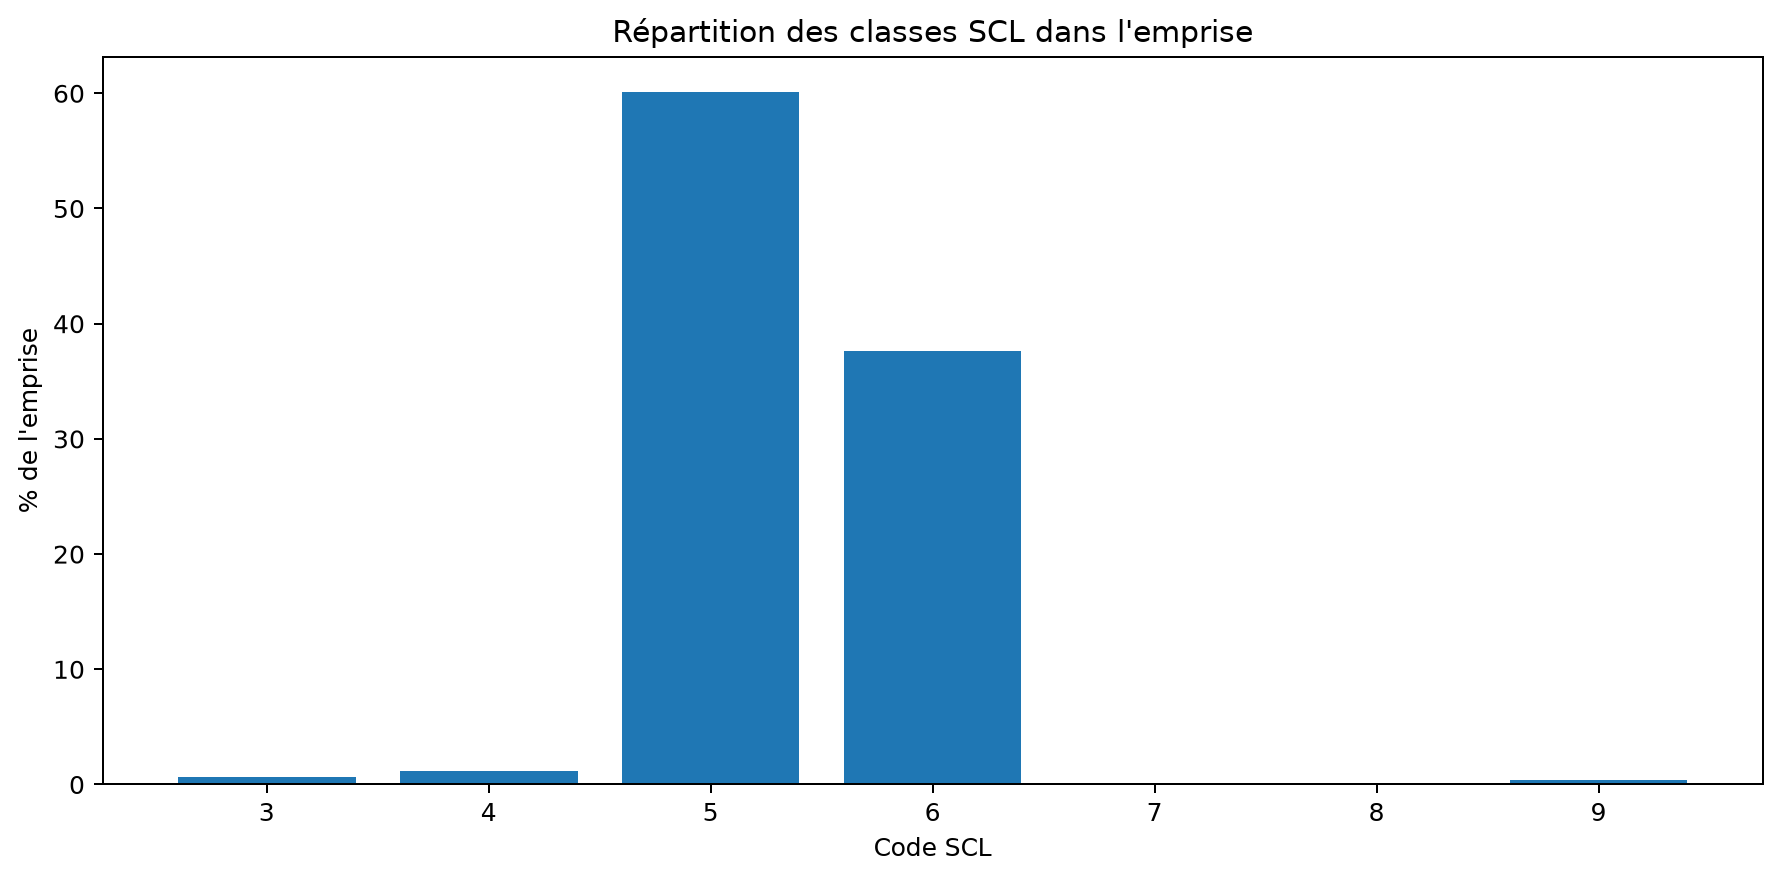

In [12]:
SCL_LABELS = {
    0: "No Data",
    1: "Saturated or defective",
    2: "Dark area pixels",
    3: "Cloud shadows",
    4: "Vegetation",
    5: "Not vegetated",
    6: "Water",
    7: "Unclassified",
    8: "Cloud medium probability",
    9: "Cloud high probability",
    10: "Thin cirrus",
    11: "Snow or ice",
}
aoi = gpd.read_file(DATA / "aoi.geojson")
with rasterio.open(DATA / "SCL.tif") as src:
    geom = [g.__geo_interface__ for g in aoi.to_crs(src.crs).geometry]
    arr, transform = mask(src, geom, crop=True, filled=False, indexes=1)
    values = arr.compressed().astype("int32")
    unique, counts = np.unique(values, return_counts=True)
    pixel_area_ha = abs(transform.a * transform.e) / 10000.0
scl = []
for value, count in zip(unique, counts):
    scl.append({
        "code": int(value),
        "classe_SCL": SCL_LABELS.get(int(value), f"Code {value}"),
        "pixels": int(count),
        "percent": float(100 * count / counts.sum()),
        "area_ha": float(count * pixel_area_ha),
    })
scl_df = pd.DataFrame(scl)
scl_df.to_csv(RESULTS / "scl_summary.csv", index=False)
display(scl_df)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(scl_df["code"].astype(str), scl_df["percent"])
ax.set_xlabel("Code SCL")
ax.set_ylabel("% de l'emprise")
ax.set_title("Répartition des classes SCL dans l'emprise")
fig.tight_layout()
fig.savefig(RESULTS / "scl.png", dpi=180, bbox_inches="tight")
plt.show()
display(IPImage(filename=str(RESULTS / "scl.png")))


## 10. Portée de l’analyse

Le tutoriel couvre le prétraitement, le contrôle de qualité, les indices spectraux et les statistiques spatiales. Les opérations de classification thématique nécessitent des données de référence et une procédure de validation distinctes.

## 11. Traçabilité des résultats

Le fichier `metrics.json` regroupe les principaux indicateurs calculés au cours de l’exécution. Il permet de conserver la provenance des données, les paramètres appliqués et les résultats du diagnostic.

In [13]:
metrics = {
    "schema": "cartomize.demonstration.metrics.v1",
    "scene": {
        "id": provenance["selected_item_id"],
        "datetime": provenance["selected_datetime"],
        "platform": provenance["platform"],
        "mgrs_tile": provenance["mgrs_tile"],
        "global_cloud_cover_percent": provenance["global_cloud_cover_percent"],
    },
    "preprocessing": {
        "status": prepared.report["status"],
        "usable_percent": float(prepared.report["usable_percent"]),
        "threshold_met": bool(prepared.report["threshold_met"]),
        "selected_scene_ids": prepared.report["selected_scene_ids"],
        "mosaic": bool(prepared.report["mosaic"]),
    },
    "indices": stats,
    "scl": scl,
    "cloud_diagnostics": {
        "scl": quality_rows,
        "spectral_fallback": spectral_rows,
        "usable_percent_after_combined_masks": float(prepared.report["usable_percent"]),
    },
    "preprocessing_comparison": {
        "input": input_info,
        "output": {
            "scene": provenance["selected_item_id"],
            "usable_percent": float(prepared.report["usable_percent"]),
        },
        "figure": "kinshasa_preprocessing_comparison.png",
        "scene_aoi_input": "kinshasa_scene_input.png",
    },
    "zonal_ndvi": pd.DataFrame(zonal.drop(columns=zonal.geometry.name)).to_dict(orient="records"),
    "products": {
        "multiband": str(Path(product["multiband"]).relative_to(RESULTS / "preprocessed")),
        "composition": str(Path(product["composition"]).relative_to(RESULTS / "preprocessed")),
        "indices": "indices.tif",
        "zonal": "ndvi_zonal.gpkg",
    },
}
(RESULTS / "metrics.json").write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(metrics["preprocessing"], indent=2, ensure_ascii=False))

{
  "status": "partial",
  "usable_percent": 98.08113005648926,
  "threshold_met": true,
  "selected_scene_ids": [
    "S2C_33MWR_20250620_0_L2A"
  ],
  "mosaic": false
}


## 12. Correspondance avec l’interface de bureau

Le guide [GUIDE_INTERFACE.md](GUIDE_INTERFACE.md) décrit les opérations équivalentes dans l’interface graphique de Cartomize.